In [ ]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt



In [ ]:
# import openpyxl

# # dataset
# df = pd.read_excel("/media/soumik/storage/MTech/ADA/Labtest/OnlineRetail.xlsx")


In [18]:
df = pd.read_csv("/media/soumik/storage/MTech/ADA/Labtest/OnlineRetail_1.csv")


In [19]:
print(df.head(n=5))

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  


In [ ]:
print(f"Number of transactions before preprocessing: {len(df)}")

# preprocessig

# drop invalid
df = df.dropna(subset=['InvoiceNo', 'StockCode'])

# Remove if InvoiceNo starts with C
df = df[
    ~df['InvoiceNo'].astype(str).str.startswith('C')
]

print(f"Number of transactions after preprocessing: {len(df)}")


Number of transactions before preprocessing: 541909
Number of transactions after preprocessing: 532621


In [22]:
# product codes to strings
df['StockCode'] = df['StockCode'].astype(str)

print(df['StockCode'])


0         85123A
1          71053
2         84406B
3         84029G
4         84029E
           ...  
541904     22613
541905     22899
541906     23254
541907     23255
541908     22138
Name: StockCode, Length: 532621, dtype: str


In [ ]:
# transaction is invoice, stockcode is eacch item
transactions = (
    df.groupby('InvoiceNo')['StockCode']
    .apply(lambda x: list(set(x)))
    .tolist()
)

n_transactions = len(transactions)

print("Total transactions:", n_transactions)

# Minimum support = 1%
min_support = 0.01
min_count = int(min_support * n_transactions + 1)

print("Minimum support count:", min_count)


Total transactions: 22064
Minimum support count: 221


In [ ]:
class Node:
    def __init__(self, item, parent):
        self.item = item
        self.count = 0
        self.parent = parent
        self.children = {}

        self.link = None

In [28]:
def build_tree(weighted_transactions, min_count):

    # frequency of each item
    frequency = {}

    for transaction, weight in weighted_transactions:
        for item in transaction:
            frequency[item] = (
                frequency.get(item, 0) + weight
            )

    # remove infrequent items
    frequency = {
        item: count
        for item, count in frequency.items()
        if count >= min_count
    }

    if not frequency:
        return None, None

    # sort
    header = {
        item: [count, None, None]
        for item, count in frequency.items()
    }

    root = Node(None, None)

    for transaction, weight in weighted_transactions:

        # keep only frequent
        items = [
            item for item in transaction
            if item in frequency
        ]

        # sort original set
        items.sort(
            key=lambda item: (-frequency[item], item)
        )

        current = root

        for item in items:

            if item not in current.children:

                new_node = Node(item, current)
                current.children[item] = new_node

                if header[item][1] is None:
                    header[item][1] = new_node
                else:
                    header[item][2].link = new_node

                header[item][2] = new_node

            current = current.children[item]
            current.count += weight

    return root, header


def fp_growth(weighted_transactions, min_count, prefix=frozenset()):

    root, header = build_tree(
        weighted_transactions,
        min_count
    )

    if header is None:
        return {}

    patterns = {}

    sorted_items = sorted(
        header.keys(),
        key=lambda item: (header[item][0], item)
    )

    for item in sorted_items:

        # new frequent itemset
        new_pattern = prefix | frozenset([item])

        # support count
        patterns[new_pattern] = header[item][0]

        # conditional pattern
        conditional_base = []

        node = header[item][1]

        while node is not None:

            path = []
            parent = node.parent

            while parent is not None and parent.item is not None:
                path.append(parent.item)
                parent = parent.parent
            
            if path:
                conditional_base.append(
                    (path, node.count)
                )

            node = node.link

        # build tree recursive
        if conditional_base:

            conditional_patterns = fp_growth(
                conditional_base,
                min_count,
                new_pattern
            )

            patterns.update(conditional_patterns)

    return patterns


In [29]:
weighted_transactions = [
    (transaction, 1)
    for transaction in transactions
]

frequent_itemsets = fp_growth(
    weighted_transactions,
    min_count
)

print("Total frequent itemsets:", len(frequent_itemsets))

Total frequent itemsets: 1567


In [ ]:
results = []

for itemset, count in frequent_itemsets.items():

    length = len(itemset)

    if length in [1, 2, 3]:

        support = count / n_transactions

        results.append({
            'Itemset': tuple(sorted(itemset)),
            'Length': length,
            'Support_Count': count,
            'Support': support,
        })

result_df = pd.DataFrame(results)

result_df = result_df.sort_values(
    by='Support',
    ascending=False
)

print("Top 10 Frequent Itemsets:")
print(result_df.head(10).to_string(index=False))


Top 10 Frequent Itemsets:
  Itemset  Length  Support_Count  Support
(85123A,)       1           2204 0.099891
(85099B,)       1           2092 0.094815
 (22423,)       1           1992 0.090283
 (47566,)       1           1686 0.076414
 (20725,)       1           1565 0.070930
 (84879,)       1           1456 0.065990
 (22197,)       1           1392 0.063089
 (22720,)       1           1389 0.062953
 (21212,)       1           1320 0.059826
 (22383,)       1           1285 0.058240


In [32]:
for length in [1, 2, 3]:

    subset = result_df[
        result_df['Length'] == length
    ].head(10)

    print(f"Top 10 Itemsets of Length {length}:")
    print(subset.to_string(index=False))

Top 10 Itemsets of Length 1:
  Itemset  Length  Support_Count  Support
(85123A,)       1           2204 0.099891
(85099B,)       1           2092 0.094815
 (22423,)       1           1992 0.090283
 (47566,)       1           1686 0.076414
 (20725,)       1           1565 0.070930
 (84879,)       1           1456 0.065990
 (22197,)       1           1392 0.063089
 (22720,)       1           1389 0.062953
 (21212,)       1           1320 0.059826
 (22383,)       1           1285 0.058240
Top 10 Itemsets of Length 2:
        Itemset  Length  Support_Count  Support
(22386, 85099B)       2            825 0.037391
 (22697, 22699)       2            768 0.034808
(21931, 85099B)       2            724 0.032814
(22411, 85099B)       2            680 0.030819
 (20725, 22383)       2            655 0.029686
 (20725, 20727)       2            641 0.029052
 (22726, 22727)       2            640 0.029007
 (22697, 22698)       2            633 0.028689
 (20725, 22384)       2            606 0.027466


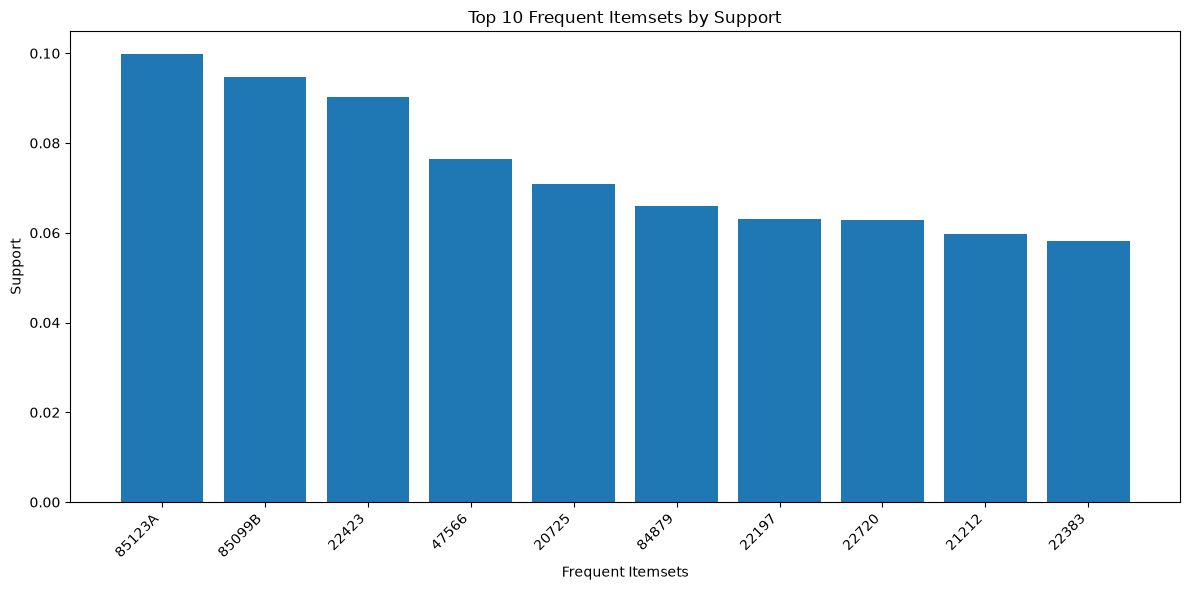

In [34]:
top10 = result_df.head(10).copy()


plt.figure(figsize=(12, 6))

# plt.bar(
#     top10['Itemset'],
#     top10['Support']
# )

labels = [
    ', '.join(itemset)
    for itemset in top10['Itemset']
]
plt.bar(
    labels,
    top10['Support']
)

plt.xlabel("Frequent Itemsets")
plt.ylabel("Support")
plt.title("Top 10 Frequent Itemsets by Support")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()
